# Extended Data: single-cell RNA panels

Makes the single-cell RNA Extended Data panels not made in a main-figure notebook.

Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **ED 2c**: marker heatmaps, whole-embryo mutants (4N) (section: Marker gene heatmaps)
- **ED 2d**: transcriptional age of whole-embryo mutants (section: Transcriptional age)
- **ED 3b**: chimerism per embryo (section: Chimerism per embryo)
- **ED 3c**: marker heatmaps, mixed chimeras (section: Marker gene heatmaps)
- **ED 4b**: epiblast and nascent mesoderm module correlation (section: Modules)
- **ED 5a**: KO vs host expression per lineage (section: KO vs host per lineage)
- **ED 5b**: maximal metacell expression by gene class (section: Expression by gene class)
- **ED 5c**: imprinted gene heatmaps (section: Imprinted gene heatmaps)
- **ED 6a**: marker heatmaps, multiome (section: Marker gene heatmaps)

Notes:
- Figures go through `out_path()` (`paths.R`), which maps `figs/...` to `git_test/figs/...`.
- Many cells are stored without outputs; their figure files are in `git_test/figs/Supp/`.

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)
source(file.path(repo_dir, "scripts/ExtData_RNA_func.r"))

In [2]:
library(dplyr)
library(ggplot2)
library(anndata)
library(tibble)
library(tgstat)
library(ggridges)
library(tidyr)
library(zoo)

cell_type_key = read.csv("./data/ref/cell_type_key.csv", row.names = 1)
imprinted_genes = c("Igf2", "Dlk1", "Meg3", "Peg3", "Peg10",
             "Dnmt3a", "Dnmt3b", "Dnmt1", "Mest", "H19", "Impact", "Airn",
             "Kcnq1ot1", "Snrpn", "Nnat", "Rian", "Inpp5f", "Plagl1", "Nap1l5", "Gnas", "Cdkn1c", "Phlda2")

- `cell_type_key`: lineage and colour per cell type.
- `imprinted_genes`: genes for ED 5c; includes Dnmt1, Dnmt3a, Dnmt3b as references.

In [3]:
markers = read.table("./data/ref/markers.txt") %>% pull(1) # %>% sort()
annotation_colors = list("cell_type" = cell_type_key %>% select(cell_type, lineage_color) %>% deframe())

## Metacell models

- Loads `RNA_mod` (`data/output/RNA_mod.RDS`, from `Fig2.ipynb`): single cells and metacell expression per dataset.

In [4]:
RNA_mod = readRDS(in_path("./data/output/RNA_mod.RDS"))

## ED 2c, 3c, 6a: marker gene heatmaps

- Rows: marker genes from `data/ref/markers.txt`, in file order.
- Columns: metacells ordered by cell type (`cell_type_key`); visceral endoderm types removed.
- Values: log2 expression minus the gene's median across shown metacells, clipped to -2..2.

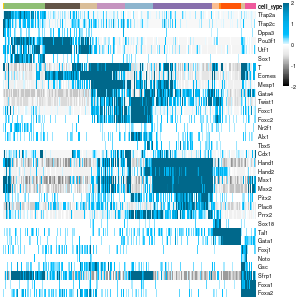

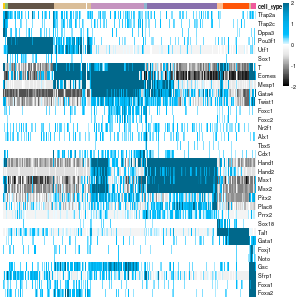

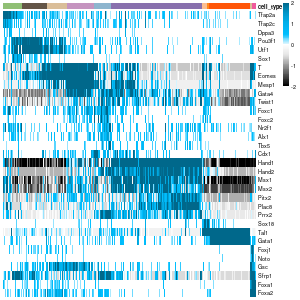

In [5]:
plot_marker_htmp("WT_4N", gns = markers)
plot_marker_htmp("DNMT_TKO_4N", gns = markers)
plot_marker_htmp("DNMT_DKO_4N", gns = markers)

**ED 2c**, whole-embryo 4N models, in `figs/Supp/marker_heatmaps/`:
- `WT_4N.pdf`, `DNMT_TKO_4N.pdf`, `DNMT_DKO_4N.pdf`

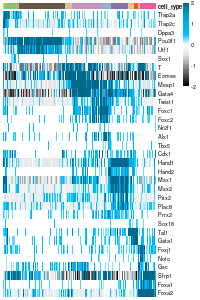

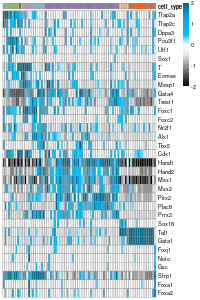

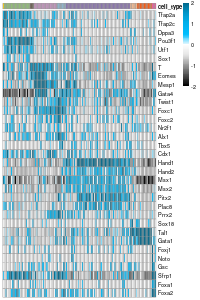

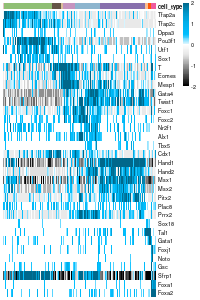

In [6]:
plot_marker_htmp("multi.WT", gns = markers, width = 5)
plot_marker_htmp("multi.DNMT_TKO_KO", gns = markers, width = 5)
plot_marker_htmp("multi.DNMT_DKO_KO", gns = markers, width = 5)
plot_marker_htmp("multi.TET_TKO_KO", gns = markers, width = 5)

**ED 6a**, multiome RNA models, in `figs/Supp/marker_heatmaps/`:
- `multi.WT.pdf`, `multi.DNMT_TKO_KO.pdf`, `multi.DNMT_DKO_KO.pdf`, `multi.TET_TKO_KO.pdf`

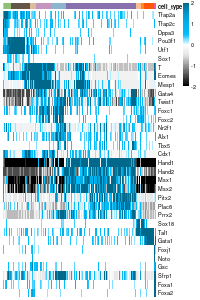

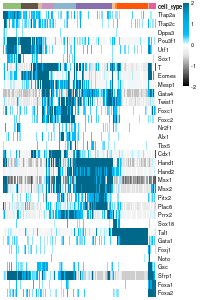

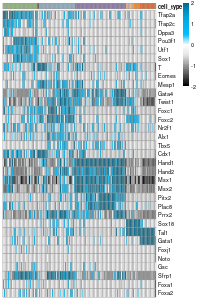

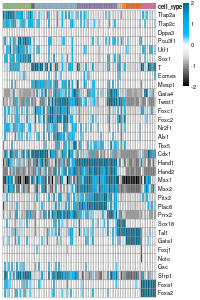

In [7]:
plot_marker_htmp("DNMT_TKO_KO", gns = markers, width = 5)
plot_marker_htmp("DNMT_TKO_host", gns = markers, width = 5)
plot_marker_htmp("DNMT_DKO_KO", gns = markers, width = 5)
plot_marker_htmp("DNMT_DKO_host", gns = markers, width = 5)

**ED 3c**, chimera KO and host fractions, in `figs/Supp/marker_heatmaps/`:
- `DNMT_TKO_KO.pdf`, `DNMT_TKO_host.pdf`, `DNMT_DKO_KO.pdf`, `DNMT_DKO_host.pdf`

## ED 5c: imprinted gene heatmaps

Same metacells and order as the marker heatmaps, but absolute log2 expression of `imprinted_genes` (scale -16 to -6), for Dnmt-TKO and -DKO KO and host.

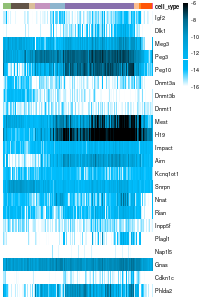

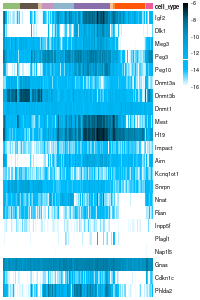

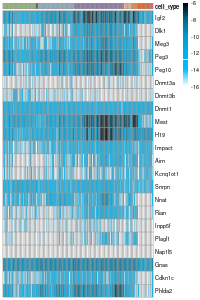

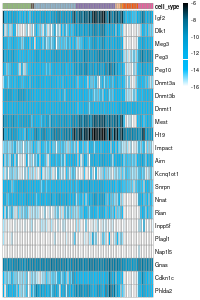

In [8]:
options(repr.plt.width = 5, repr.plot.height = 7.5)
plot_abs_htmp("DNMT_TKO_KO", gns = imprinted_genes, width = 5)
plot_abs_htmp("DNMT_TKO_host", gns = imprinted_genes, width = 5)
plot_abs_htmp("DNMT_DKO_KO", gns = imprinted_genes, width = 5)
plot_abs_htmp("DNMT_DKO_host", gns = imprinted_genes, width = 5)

**ED 5c**, in `figs/Supp/imprinted_heatmaps/`:
- `DNMT_TKO_KO.pdf`, `DNMT_TKO_host.pdf`, `DNMT_DKO_KO.pdf`, `DNMT_DKO_host.pdf`

## ED 4b: epiblast and nascent mesoderm modules

- Modules: epiblast (Utf1-correlated) and nascent mesoderm genes from the earlier TET paper (listed in Methods and the second cell below).
- WT expression: atlas metacells (`data/MC_models/atlas_sharpened.h5ad`), median-centred log2, averaged per cell type; visceral endoderm excluded.
- Heatmap: Pearson correlation between module genes across cell types.

In [9]:
library(tgstat)

atlas = read_h5ad("./data/MC_models/atlas_sharpened.h5ad")

egc = t(as.matrix(atlas$X))
legc = log2(1e-5+egc)
lfp = legc - apply(legc, 1, median)

mc_type = atlas$obs$cell_type
names(mc_type) = atlas$obs_names
lfp_type = t(tgs_matrix_tapply(lfp, mc_type, mean))

In [10]:
# Modules from TET paper
epiblast_module = c("Dtx1", "Enpp3", "Foxd3", "L1td1", "Mal2", "Mkrn1", "Pdzd4", "Pim2", "Pipox", "Pou3f1", "Slc35d3", "Slc35f2", "Slc7a3", "Ugt8a", "Utf1")
nm_module = c("Apln", "Cyp26a1", "Eomes", "Evx1", "Fgf8", "Frzb", "Fst", "Gas1", "Mesp1", "Mixl1", "Snai1", "Sp5", "T", "Tdgf1", "Wnt3")

In [11]:
cts_to_keep = setdiff(names(annotation_colors$cell_type), c('Visceral endoderm','ExE visceral endoderm','Visceral endoderm_anterior'))
cts_to_keep = cts_to_keep[cts_to_keep %in% colnames(lfp_type)]

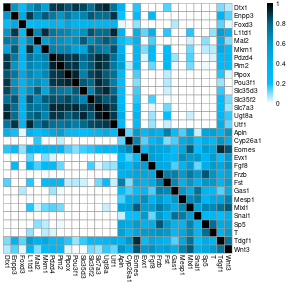

In [12]:
options(repr.plot.width = 5, repr.plot.height = 5)

breaks = seq(0,1, length.out = 1000)
custom_palette <- colorRampPalette(c("white", "deepskyblue1", "deepskyblue2", "deepskyblue3", "deepskyblue4", "black"))(1000)

show_fig("./figs/Supp/modules.pdf", draw = pheatmap::pheatmap(tgs_cor(t(rbind(lfp_type[epiblast_module,cts_to_keep], lfp_type[nm_module,cts_to_keep]))),
                   cluster_rows = F, cluster_cols = F,
                   breaks = breaks, color = custom_palette,
                   width = 6, height = 6))

**ED 4b**: both modules in one matrix: `figs/Supp/modules.pdf`.

## ED 5a: KO vs host per lineage

- Input: KO and host pseudo-bulk counts from `prep_single_cell()` (`data/output/mko.RDS`, `mhost.RDS`; see `prep/ko_vs_host.ipynb`).
- Per lineage: log2 frequency in KO (x) vs host (y), Pearson r in the title; genes as in Fig. 2e.
- Black: q < 0.01 in both Dnmt-TKO and -DKO. Light blue: Dahlet et al., 2020 germline genes.

In [13]:
source(file.path(repo_dir, "scripts/single_cell_func.r"))
sc <- prep_single_cell()

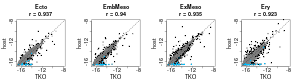

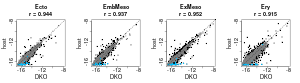

In [14]:
show_fig("./figs/Supp/S5A_TKO.png", w = 3600, h = 1000, res = 300, draw = {
layout(matrix(1:4,nrow=1))
par(mar=c(5,5,6,3))
for(ty in c("Ecto","EmbMeso", "ExMeso", "Ery")) {
   tko_nm = sprintf("DNMT_TKO.%s", ty)
   dko_nm = sprintf("DNMT_DKO.%s", ty)
    
   sig_layer = sc$sig_consistent %>% filter(layer == ty) %>% pull(gene)
   gene_col = ifelse(sc$plotted_genes %in% sig_layer, "black", "grey50")
   r = cor(log2(1e-5+sc$mko_fe)[sc$f_dlt, tko_nm], log2(1e-5+sc$mhost_fe)[sc$f_dlt, tko_nm])
   plot(log2(1e-5+sc$mko_fe)[sc$f_dlt, tko_nm], log2(1e-5+sc$mhost_fe)[sc$f_dlt, tko_nm], col=gene_col, pch=19, cex=0.8, cex.lab = 2, cex.axis = 2, cex.main = 2, main=sprintf("%s\nr = %s",ty, round(r,3)), 
        xlab="TKO", ylab="host", xlim=c(log2(1e-5), -8), ylim=c(log2(1e-5), -8))
   points(log2(1e-5+sc$mko_fe)[sc$f_dlt, tko_nm][sc$weber_highlight], log2(1e-5+sc$mhost_fe)[sc$f_dlt, tko_nm][sc$weber_highlight], col="deepskyblue", pch=19, cex=0.8)
   abline(h = 0)
   abline(v = 0)

   abline(a = 0, b = 1, lty = 2)
}
})

show_fig("./figs/Supp/S5A_DKO.png", w = 3600, h = 1000, res = 300, draw = {
layout(matrix(1:4,nrow=1))
par(mar=c(5,5,6,3))
for(ty in c("Ecto","EmbMeso", "ExMeso", "Ery")) {
   tko_nm = sprintf("DNMT_TKO.%s", ty)
   dko_nm = sprintf("DNMT_DKO.%s", ty)
    
   sig_layer = sc$sig_consistent %>% filter(layer == ty) %>% pull(gene)
   gene_col = ifelse(sc$plotted_genes %in% sig_layer, "black", "grey50")
    
   r = cor(log2(1e-5+sc$mko_fe)[sc$f_dlt, dko_nm], log2(1e-5+sc$mhost_fe)[sc$f_dlt, dko_nm])
   plot(log2(1e-5+sc$mko_fe)[sc$f_dlt, dko_nm], log2(1e-5+sc$mhost_fe)[sc$f_dlt, dko_nm], col=gene_col, pch=19, cex=0.8, cex.lab = 2, cex.axis = 2, cex.main = 2, main=sprintf("%s\nr = %s",ty, round(r,3)), 
        xlab="DKO", ylab="host", xlim=c(log2(1e-5), -8), ylim=c(log2(1e-5), -8))
   points(log2(1e-5+sc$mko_fe)[sc$f_dlt, dko_nm][sc$weber_highlight], log2(1e-5+sc$mhost_fe)[sc$f_dlt, dko_nm][sc$weber_highlight], col="deepskyblue", pch=19, cex=0.8)
   abline(h = 0)
   abline(v = 0)

   abline(a = 0, b = 1, lty = 2)
}
})

**ED 5a** (inline image shows DKO):
- `figs/Supp/S5A_TKO.png`
- `figs/Supp/S5A_DKO.png`

## ED 5b: maximal expression by gene class

Per gene, the maximum log2 expression across metacells, as ridges per class:
- Ribosomal genes (`^Rpl|^Rps`)
- Key TFs (`data/ref/markers.txt`)
- Dahlet et al., 2020 germline genes (`data/download/weber_genes.csv`, `upregulated_germline`), present in both atlas and TKO model

Models: atlas, Dnmt-TKO 4N, Dnmt-DKO 4N.

In [15]:
tko = read_h5ad("./data/MC_models/mars_DNMT_TKO_4N_ff_metacells_projected.h5ad")
dko = read_h5ad("./data/MC_models/mars_DNMT_DKO_4N_ff_metacells_projected.h5ad")

tko_egc = t(as.matrix(tko$X))
tko_legc = log2(1e-5+tko_egc)

dko_egc = t(as.matrix(dko$X))
dko_legc = log2(1e-5+dko_egc)

In [16]:
markers = read.table("./data/ref/markers.txt") %>% pull(1)
tab_weber = read.csv("./data/download/weber_genes.csv",stringsAsFactors=F)
weber_germ = intersect(rownames(legc), tab_weber$gene[tab_weber$class=="upregulated_germline"])
ribo = grep("^Rpl|^Rps", rownames(legc), v=T)

In [17]:
weber_f = weber_germ[weber_germ %in% intersect(rownames(legc), rownames(tko_legc))]

In [18]:
df_l = lapply(list(legc, tko_legc, dko_legc), make_df)
names(df_l) = c("atlas", "TKO", "DKO")

In [19]:
df_l$atlas$source = "Atlas"
df_l$TKO$source = "DNMT TKO"
df_l$DKO$source = "DNMT DKO"

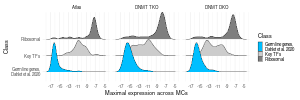

In [20]:
options(repr.plot.width = 15, repr.plot.height = 5)

p_class = do.call(rbind, df_l) %>% 
    mutate(source = factor(source, levels = c("Atlas", "DNMT TKO", "DNMT DKO"))) %>%
    ggplot(aes(max, Class, fill = Class)) + geom_density_ridges() + theme_ridges() + 
            theme(legend.position = "none", 
                  axis.text = element_text(size = 16), 
                  axis.title = element_text(size = 18),     
                  strip.text = element_text(size = 16),
                  plot.title = element_text(size = 20, hjust = 0.5, face="bold")) + 
            xlab("Atlas Maximal Expression") +
            scale_fill_manual(values = c("deepskyblue", "grey80", "grey50")) +
            scale_x_continuous(breaks = seq(-17, -4, by = 2)) +
            facet_wrap(~source) + theme_minimal(base_size = 20) + xlab("Maximal expression across MCs")

show_fig("./figs/Supp/S5B_gene_expression_by_class.pdf", p_class, width = 15, height = 5)

**ED 5b**: `figs/Supp/S5B_gene_expression_by_class.pdf`.

In [21]:
options(repr.plot.width = 7, repr.plot.height = 7)

## ED 3b: chimerism per embryo

% GFP-positive cells per embryo, by genotype (TKO clones pooled; DKO) and embryonic day.

- Input: `data/ref/chimerism_percentages.csv`, embryos in `data/output/embryo_orders.RDS`.
- Bars are median ± SD.
- Jitter uses seed 1; the published panel used unseeded jitter, so point positions differ from it.

In [22]:
embryo_orders <- readRDS(file = in_path("./data/output/embryo_orders.RDS"))
embryos_kept <- unname(unlist(embryo_orders))

In [23]:
chim_perc <- read.csv("./data/ref/chimerism_percentages.csv") %>% select(1:4)
colnames(chim_perc) = tolower(gsub("\\.", "_", colnames(chim_perc)))
colnames(chim_perc)[2] = "perc_str"

chim_perc = chim_perc %>% mutate(perc = as.numeric(gsub("%", "", perc_str))) %>% filter(embryo_name %in% embryos_kept, !is.na(perc)) %>%
    mutate(genotype = case_when(genotype %in% c("DnmtTKO5", "DnmtTKO6") ~ "TKO",
                                genotype == "DnmtDKO" ~ "DKO"),
           name = paste(genotype, embryonic_day, sep = " "))

error_bars = chim_perc %>%
        group_by(name) %>% summarize(median = median(perc, na.rm = T),
                                     sd_pos = median + sd(perc, na.rm = T),
                                     sd_neg = median - sd(perc, na.rm = T))  

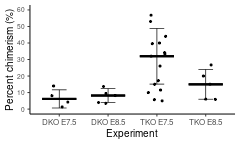

In [24]:
options(repr.plot.width = 5, repr.plot.height = 3)

p_chim = ggplot() +
        geom_jitter(data = chim_perc, aes(x = name, y = perc), position = position_jitter(width = 0.2, seed = 1)) +
        geom_errorbar(data = error_bars, aes(x = name, ymin=sd_neg, ymax=sd_pos), width = 0.3) + 
        geom_errorbar(data = error_bars, aes(x = name, ymin = median, ymax = median), color = "black", size = 1.5, width = 0.7) + 
        xlab("Experiment") + ylab("Percent chimerism (%)") +
        theme_classic(base_size = 15) + theme(axis.text.y = element_text(size = 10), plot.title = element_text(size = 16, hjust = 0.5)) +
        scale_y_continuous(limits = c(0, 60), breaks = seq(0, 60, by = 10)) +
        scale_fill_identity()

show_fig("./figs/Supp/chimerism.pdf", p_chim, width = 5, height = 3)

Output: `figs/Supp/chimerism.pdf`.

## ED 2d: transcriptional age
- Jitter uses seed 1; the published panels used unseeded jitter, so point positions differ from them.

Inferred transcriptional age of each 4N control, TKO and DKO embryo, split by dissection day, with median ± SD.

Inputs:
- `my_data/ref/transcriptional_time_best_ref.csv` under `dnmt_final_dir` (from `prep/transcriptional_time.ipynb`)
- `data/ref/embryo_classification.csv` (mutant dissection days)
- `my_data/ref/WT_4N_dissection_day.csv` (controls; Ctrl3_3 excluded)
- `data/output/embryo_orders.RDS`

Re-running `prep/transcriptional_time.ipynb` writes under `git_test/external/`; this panel reads that copy with `use_regenerated_inputs = TRUE` (`paths.R`).

In [25]:
best_ref = read.csv(in_path(file.path(dnmt_final_dir, "my_data/ref/transcriptional_time_best_ref.csv")))
embryo_orders = readRDS(in_path("./data/output/embryo_orders.RDS"))

emb_nomenclature = data.table::fread("./data/ref/embryo_classification.csv", header = T) %>% select(1,2)
control_dissection_day = data.table::fread(file.path(dnmt_final_dir, "my_data/ref/WT_4N_dissection_day.csv")) %>% 
    filter(embryo != "Ctrl3_3")

emb_nomenclature = rbind(emb_nomenclature, control_dissection_day)

In [26]:
TKO_embryos = embryo_orders[["DNMT_TKO_4N"]]
TKO_emb_to_diss = emb_nomenclature %>% filter(embryo %in% TKO_embryos) %>% deframe()

#

DKO_embryos = embryo_orders[["DNMT_DKO_4N"]]
DKO_emb_to_diss = emb_nomenclature %>% filter(embryo %in% DKO_embryos) %>% deframe()

# 

WT_embryos = embryo_orders[["WT_4N"]]
WT_emb_to_diss = control_dissection_day %>% filter(embryo %in% WT_embryos) %>% deframe()

In [27]:
df_ctrl = best_ref %>% filter(embryo %in% WT_embryos) %>% pivot_wider(id_cols = embryo, names_from = KO_host, values_from = transcriptional_time) %>% 
    rename(transcriptional_time = KO) %>% mutate(dissection_day = WT_emb_to_diss[embryo], group = "Ctrl")

df_TKO = best_ref %>% filter(embryo %in% TKO_embryos) %>% pivot_wider(id_cols = embryo, names_from = KO_host, values_from = transcriptional_time) %>% 
    rename(transcriptional_time = KO) %>% mutate(dissection_day = TKO_emb_to_diss[embryo], group = "TKO")

df_DKO = best_ref %>% filter(embryo %in% DKO_embryos) %>% pivot_wider(id_cols = embryo, names_from = KO_host, values_from = transcriptional_time) %>% 
    rename(transcriptional_time = KO) %>% mutate(dissection_day = DKO_emb_to_diss[embryo], group = "DKO")

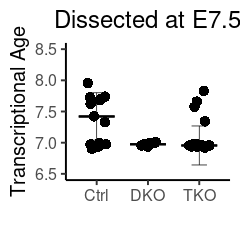

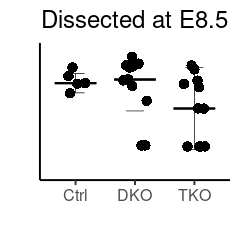

In [28]:
options(repr.plot.width = 5, repr.plot.height = 5)

# E7.5
plot_df = rbind(df_ctrl, df_TKO, df_DKO) %>% filter(dissection_day == "E7.5")
error_bars = plot_df %>% group_by(group) %>% summarize(median = median(transcriptional_time, na.rm = T),
                                                                sd_pos = median + sd(transcriptional_time, na.rm = T),
                                                                sd_neg = median - sd(transcriptional_time, na.rm = T))

p_7.5 <- ggplot() + geom_errorbar(data = error_bars, aes(x=group, ymin=sd_neg, ymax=sd_pos), width = 0.3) + 
    geom_errorbar(data = error_bars, aes(x = group, ymin = median, ymax = median), color = "black", size = 1.5, width = 0.7) + 
    geom_jitter(data = plot_df, aes(group, transcriptional_time), size = 7, shape=16, position=position_jitter(0.2, seed = 1)) +
    ylim(6.5, 8.5) + xlab("") + ylab("Transcriptional Age") + ggtitle("Dissected at E7.5") + theme_classic(base_size = 30) + theme(plot.title = element_text(hjust=0.5))
show_fig("./figs/Supp/transcriptional_age_E7.5.pdf", p_7.5, width = 5, height = 5)

# E8.5
plot_df = rbind(df_ctrl, df_TKO, df_DKO) %>% filter(dissection_day == "E8.5")
error_bars = plot_df %>% group_by(group) %>% summarize(median = median(transcriptional_time, na.rm = T),
                                                                sd_pos = median + sd(transcriptional_time, na.rm = T),
                                                                sd_neg = median - sd(transcriptional_time, na.rm = T))

p_8.5 <- ggplot() + geom_errorbar(data = error_bars, aes(x=group, ymin=sd_neg, ymax=sd_pos), width = 0.3) + 
    geom_errorbar(data = error_bars, aes(x = group, ymin = median, ymax = median), color = "black", size = 1.5, width = 0.7) + 
    geom_jitter(data = plot_df, aes(group, transcriptional_time), size = 7, shape=16, position=position_jitter(0.2, seed = 1)) +
    ylim(6.5, 8.5) + xlab("") + ylab("") + ggtitle("Dissected at E8.5") + theme_classic(base_size = 30) + 
    theme(plot.title = element_text(hjust=0.5), axis.text.y=element_blank(), axis.ticks.y=element_blank())
show_fig("./figs/Supp/transcriptional_age_E8.5.pdf", p_8.5, width = 5, height = 5)

**ED 2d**:
- `figs/Supp/transcriptional_age_E7.5.pdf`
- `figs/Supp/transcriptional_age_E8.5.pdf`